MD# 02 · Integrated atlas: cell types, mixing, agreement with authors

Uses the per-cell output of `R/08_transfer_and_outputs.R` (`results/PD11_final_cell_annotations.csv.gz`: labels and UMAP coordinates, **no expression data**) and the cluster tables of steps 05–07.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
# Notebooks run from the project root so that results/ and config/ resolve.
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
cells = pd.read_csv("results/PD11_final_cell_annotations.csv.gz", low_memory=False)
pal = pd.read_csv("config/display_names.csv").drop_duplicates("cell_type").set_index("cell_type").color.to_dict()
print(f"{len(cells):,} annotated nuclei · {cells.dataset.nunique()} datasets · {cells.donor.nunique()} donors")
ct = cells.cell_type.value_counts(); pd.DataFrame({"nuclei": ct, "pct": (100*ct/ct.sum()).round(2)})

38,895 annotated nuclei · 11 datasets · 209 donors


,nuclei,pct
cell_type,,
Oligo,16655,42.82
Astro,4691,12.06
EN,3000,7.71
OPC,2764,7.11
Micro_PVM,2675,6.88
Unresolved,2611,6.71
IN,2564,6.59
MSN,1560,4.01
DA_Neu,1212,3.12


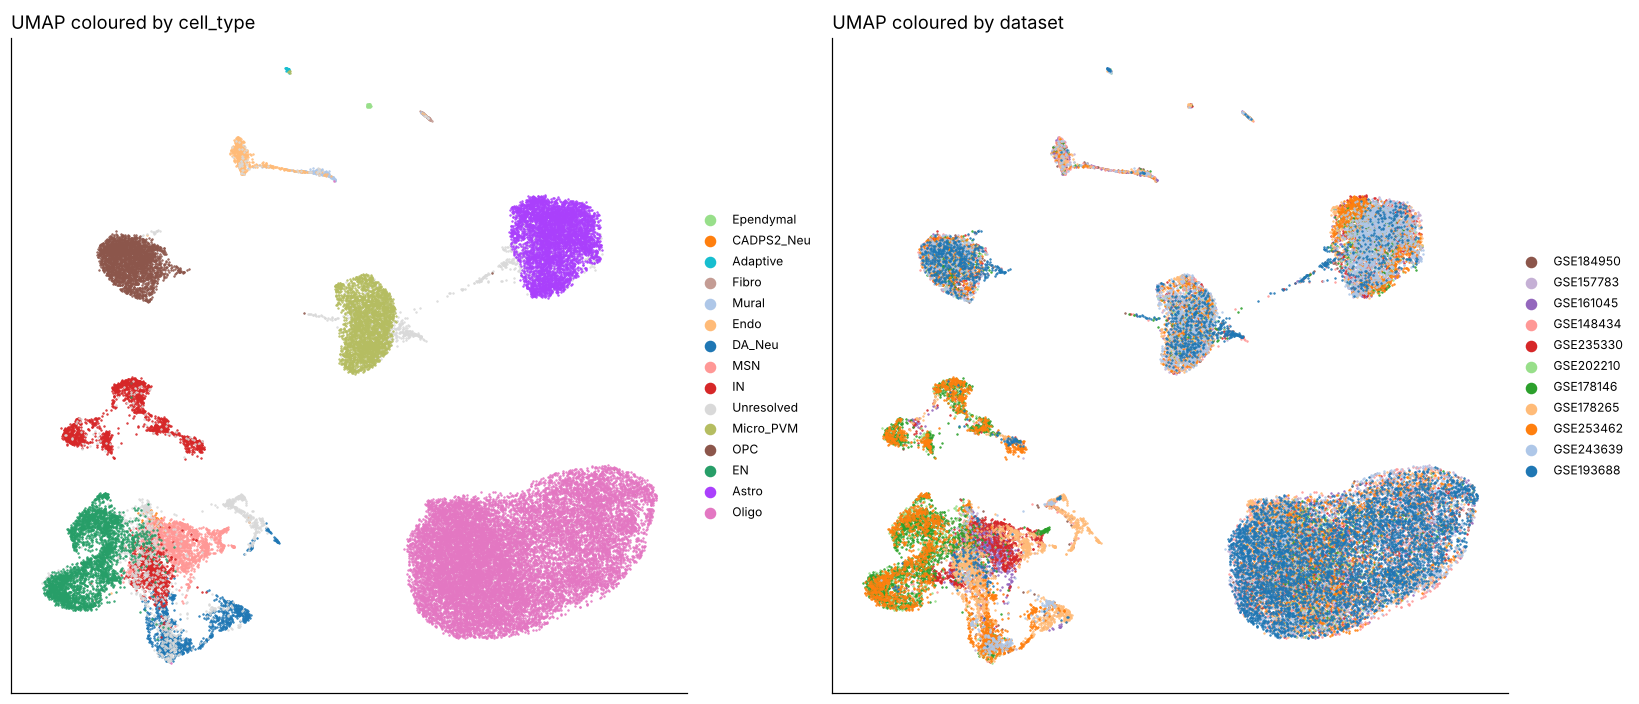

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, col in zip(axs, ["cell_type", "dataset"]):
    cats = cells[col].value_counts().index
    cmap = pal if col == "cell_type" else dict(zip(cats, plt.cm.tab20.colors))
    for c in cats[::-1]:
        s = cells[cells[col] == c]
        ax.scatter(s.UMAP_1, s.UMAP_2, s=0.3, color=cmap.get(c, "#999"), label=c, rasterized=True)
    ax.legend(markerscale=12, fontsize=8, frameon=False, loc="center left", bbox_to_anchor=(1, .5))
    ax.set_title(f"UMAP coloured by {col}", loc="left"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

MD## Cell-type mix per dataset
Each dataset should show the cell types of its brain region (MSN in striatum, EN in cortex, DA_Neu only in midbrain).

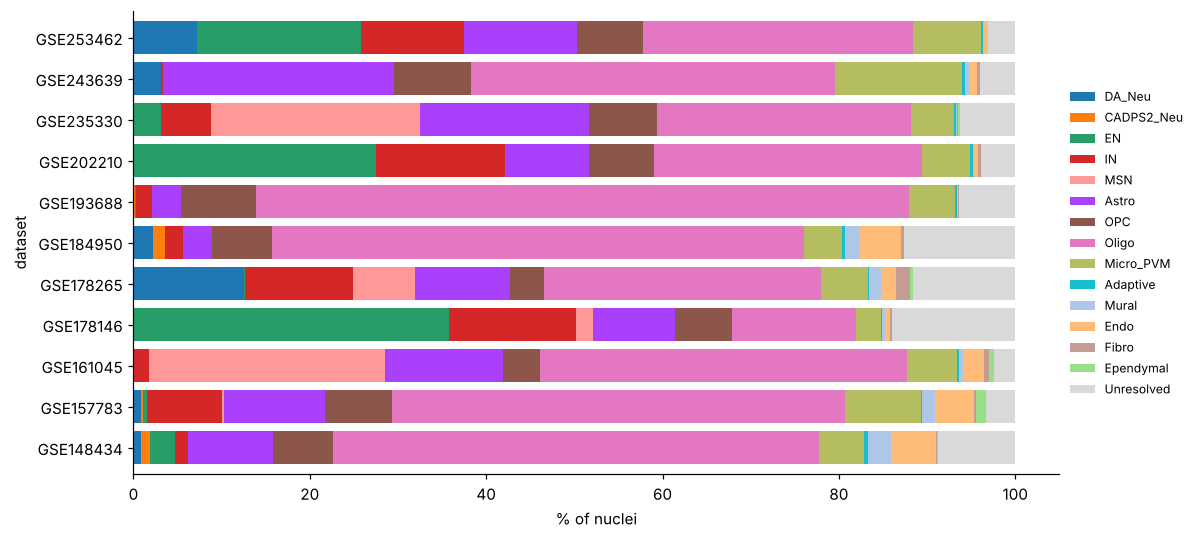

cell_type,DA_Neu,CADPS2_Neu,EN,IN,MSN,Astro,OPC,Oligo,Micro_PVM,Adaptive,Mural,Endo,Fibro,Ependymal,Unresolved
dataset,,,,,,,,,,,,,,,
GSE148434,0.9,1.0,2.8,1.4,0.0,9.7,6.9,55.1,5.1,0.4,2.6,5.1,0.1,0.1,8.7
GSE157783,0.8,0.3,0.5,8.5,0.1,11.5,7.6,51.4,8.6,0.1,1.5,4.4,0.2,1.1,3.4
GSE161045,0.0,0.0,0.1,1.7,26.7,13.4,4.2,41.6,5.7,0.2,0.5,2.4,0.5,0.6,2.5
GSE178146,0.0,0.0,35.8,14.4,1.9,9.2,6.5,14.1,2.8,0.0,0.3,0.6,0.2,0.0,13.9
GSE178265,12.5,0.0,0.1,12.3,7.0,10.7,3.9,31.5,5.3,0.1,1.3,1.7,1.6,0.4,11.5
GSE184950,2.2,1.4,0.0,2.0,0.0,3.3,6.8,60.3,4.4,0.3,1.7,4.7,0.3,0.0,12.6
GSE193688,0.1,0.1,0.1,1.8,0.0,3.3,8.6,74.0,5.3,0.2,0.1,0.0,0.1,0.0,6.4
GSE202210,0.0,0.0,27.5,14.6,0.0,9.6,7.3,30.5,5.4,0.3,0.2,0.4,0.3,0.0,3.9
GSE235330,0.0,0.0,3.1,5.6,23.7,19.2,7.7,28.8,5.0,0.2,0.1,0.0,0.0,0.3,6.3


In [4]:
frac = pd.crosstab(cells.dataset, cells.cell_type, normalize="index")
order = [c for c in pal if c in frac.columns]
ax = (100*frac[order]).plot.barh(stacked=True, figsize=(11, 5), color=[pal[c] for c in order], width=.8)
ax.legend(fontsize=8, ncol=1, frameon=False, loc="center left", bbox_to_anchor=(1, .5)); ax.set_xlabel("% of nuclei")
plt.tight_layout(); plt.show()
(100*frac[order]).round(1)

MD## Agreement with the authors' own labels (L1, where available)

In [5]:
a = cells.dropna(subset=["author_L1"])
a = a[a.celltype_L1 != "Unresolved"]
agree = (a.author_L1 == a.celltype_L1).mean()
print(f"{len(a):,} nuclei with an author label; agreement {agree:.1%}")
pd.crosstab(a.author_L1, a.celltype_L1)

2,200 nuclei with an author label; agreement 99.5%


celltype_L1,Astrocyte,Ependymal,Microglia/Myeloid,Neuron,OPC,Oligodendrocyte,T cell,Vascular
author_L1,,,,,,,,
Astrocyte,259,0,0,0,0,0,0,0
Ependymal,2,25,0,0,0,0,0,0
Microglia/Myeloid,0,0,200,0,0,0,3,0
Neuron,0,0,0,275,0,0,0,0
OPC,1,0,0,0,167,0,0,0
Oligodendrocyte,1,0,2,0,0,1131,0,1
Vascular,0,0,0,0,0,0,0,133


MD## Dataset mixing per fine cluster
`n_datasets` = how many datasets contribute to the cluster. Glial clusters should be shared by most datasets; neurons separate by region.

In [6]:
mix = pd.read_csv("results/PD11_cluster_dataset_mixing.csv")
mix["lineage"] = mix.cluster_fine.str.split("_").str[0]
s = mix.assign(shared8=mix.n_datasets >= 8).groupby("lineage").apply(lambda g: pd.Series({
    "clusters": len(g), "nuclei": g.n_cells.sum(), "pct_nuclei_in_clusters_with_8plus_datasets": round(100*g.n_cells[g.shared8].sum()/g.n_cells.sum(), 1)}))
s

,clusters,nuclei,pct_nuclei_in_clusters_with_8plus_datasets
lineage,,,
Astrocyte,16.0,5382.0,99.1
Ependymal,1.0,67.0,0.0
Microglia/Myeloid,16.0,3255.0,94.3
Neuron,25.0,9670.0,50.3
OPC,1.0,2764.0,100.0
Oligodendrocyte,2.0,16655.0,100.0
T cell,1.0,82.0,100.0
Vascular,11.0,1020.0,94.2


MD## Marker evidence (dot plots written by R steps 06 and 07)
Each cell type is called from a marker panel (`config/marker_panels_v2.csv`): a cluster is named only if ≥ 2 panel markers are detected in ≥ 30 % of its nuclei.

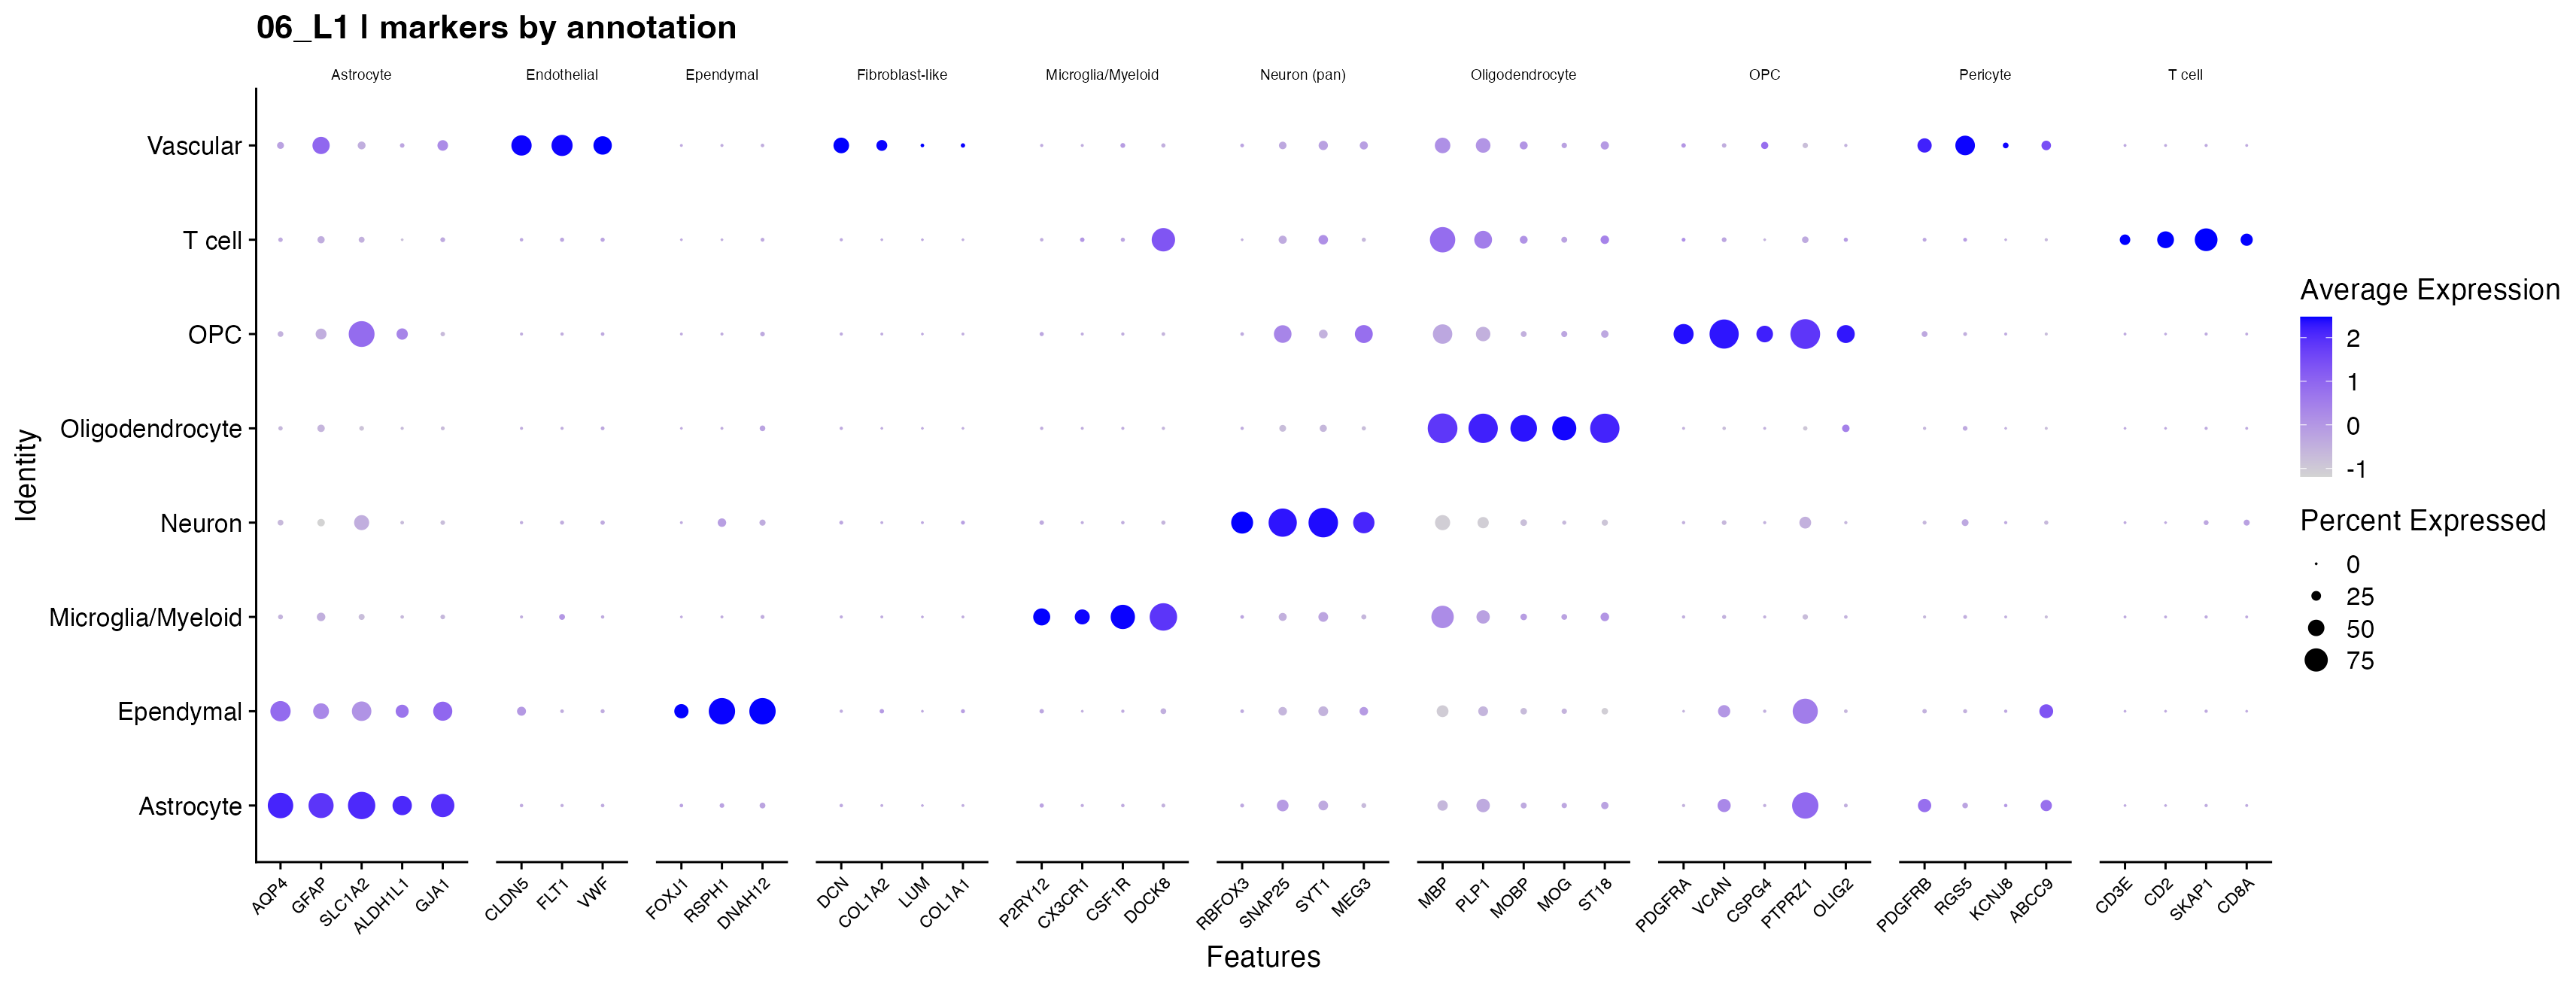

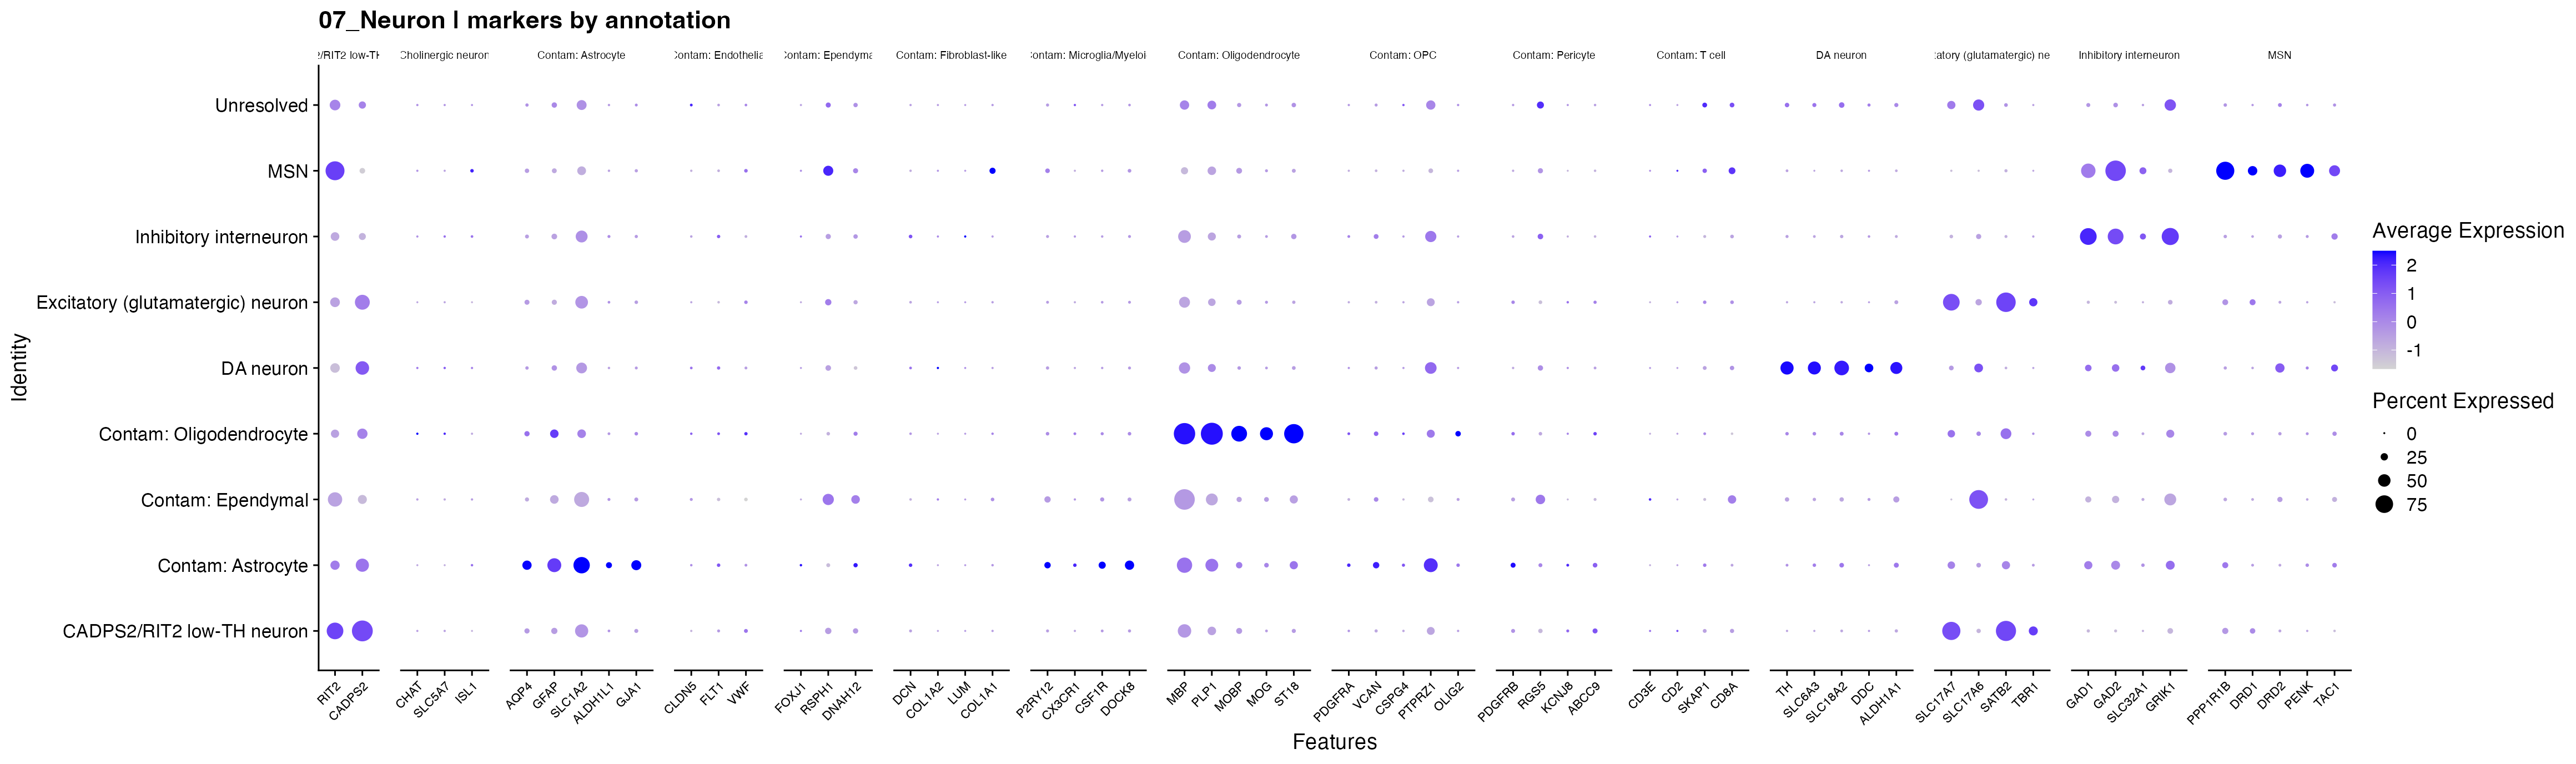

In [7]:
display(Image("plots/06_L1_dotplot_by_annotation.png", width=900))
display(Image("plots/07_Neuron_dotplot_by_annotation.png", width=900))